# Extrapolaw Demo

A scaling analysis answers: *if I train with 20x more compute, what loss will I get,
and which model size, data and hyperparameters should I use?* It does this by
training many smaller models, fitting a scaling law to them, and then extrapolating
to the target cost.

Where this notebook gets to, extrapolating 20x beyond the largest run:

<table>
  <tr>
    <td align="center"><img src="static/chinchilla_loss_over_cost.png" width="360"><br><b>Loss</b>: a power law through the compute-loss frontier</td>
    <td align="center"><img src="static/total_cells_over_cost.png" width="360"><br><b>A hyperparameter</b>: the data, <code>total_cells</code>, of the frontier runs</td>
  </tr>
</table>

Extrapolaw automates the four parts of that:

1. **Acquisition.** Deciding which small runs to train within a compute budget:
   random search (the default), Chinchilla's approach 1, CARBS, or **ScAn**, Bayesian
   optimization that picks the runs that reveal most about the best loss at the target
   compute.
2. **Prediction.** `extrapolaw.predict` fits the runs with a power law, Chinchilla's
   $L(N, D)$ or a Gaussian process, and returns the loss, the compute-optimal model
   size and data, and a full config at any target compute.
3. **Running at scale.** Many workers, processes, Slurm jobs or machines, share one
   FLOP budget through the filesystem, configs can be handed off to jobs that report
   back later, and a single run can train on many GPUs with PyTorch DDP.
4. **Visualization.** `extrapolaw.predict` writes the scaling fits of the loss and of
   every downstream metric, the predictions at the target compute and how they
   converged as runs finished; `acquire` adds live plots.

This notebook scales [TabPFN](https://github.com/PriorLabs/TabPFN), a transformer
for tabular data, on a surrogate benchmark built from thousands of real training
runs.

## Installation
Requires Python 3.11+. In Colab, run the cell below; locally, see the
[README](README.md).

In [ ]:
!git clone --depth 1 https://github.com/automl/extrapolaw.git /content/extrapolaw
%cd /content/extrapolaw/tutorials
!pip install -e "/content/extrapolaw[carbs]"
# Surrogate benchmark of TabPFN, it makes every run take a fraction of a second
!pip install scan-bench

In [1]:
import logging
import os

# The surrogates run in forked worker processes later on, which needs a single
# OpenMP thread (set before they load)
os.environ["OMP_NUM_THREADS"] = "1"
import multiprocessing as mp
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

from IPython.display import Image, display
from scan_bench import TabPFNTarget

import extrapolaw
import tabpfn_scan_bench as tabpfn

logging.basicConfig(level=logging.WARNING)
logging.getLogger("extrapolaw").setLevel(logging.INFO)
warnings.filterwarnings("ignore")


def show(*images, width=480):
    """Show PNG files, e.g. the plots of a run's `summary/`."""
    for image in images:
        display(Image(filename=image, width=width))

/home/alipourn/extrapolaw/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The pipeline

`evaluate_pipeline` is the function `extrapolaw.acquire` calls with every config. It
trains a model and returns what the scaling analysis needs: the loss to minimize, the
training cost, the model size and data, and optionally downstream performances and
the inference cost.

Here, the surrogate benchmark of `scan_bench` stands in for the training: it predicts
what a TabPFN training run would reach, its validation loss and its negative
log-likelihood on real tabular datasets, a **downstream** metric.

In [2]:
loss_benchmark = tabpfn.get_benchmark(TabPFNTarget.VAL_LOSS)
nll_benchmark = tabpfn.get_benchmark(TabPFNTarget.NLL)  # Fitted on first use, ~20s


def evaluate_pipeline(**config) -> dict:
    """Train TabPFN with `config`, here: ask the surrogates what it would reach."""
    run = tabpfn.build_config(**config)
    flops_per_cell = tabpfn.flops_estimator(**{**config, "total_cells": 1})
    return {
        "objective_to_minimize": loss_benchmark.query(run)["predictions"]["mean"],
        "cost": flops_per_cell * run.total_cells,  # Training FLOPs
        "inference_cost": flops_per_cell / 3,  # FLOPs of a forward pass over one cell
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "downstream_performances": {
            "real_nll": nll_benchmark.query(run)["predictions"]["mean"]
        },
    }

In [3]:
config = dict(total_cells=2**25, effective_batch_size=64, lr=1e-3, embedding_size=16, num_layers=4)
evaluate_pipeline(**config)

{'objective_to_minimize': 1.094,
 'cost': 5459968705691.68,
 'inference_cost': 54239.91586458365,
 'n_params': 19402,
 'n_data': 33554432,
 'downstream_performances': {'real_nll': 1.047}}

The benchmark also tells the model size and the training cost of a config without
running it. `acquire` uses the cost estimator to keep every run within
`max_cost_per_config`, and `predict` uses both to turn a predicted model size into a
config.

In [4]:
print(f"{tabpfn.parameters_estimator(**config):.3e} parameters")
print(f"{tabpfn.flops_estimator(**config):.3e} FLOPs")

1.940e+04 parameters
5.460e+12 FLOPs


## The search space

The search space is the most important design decision in a study. It defines every
parameter of a run: its type, its scale (log, linear, ...), its range and its
constraints. If it is badly defined, no optimizer can make up for it. Mark the
parameters that drive compute cost with `is_compute_scaling=True`: the scaling
optimizers lay out their runs along these axes.

The model size is determined by `embedding_size` and `num_layers`, the amount of data by
`total_cells`.

In [5]:
class TabPFNSpace(extrapolaw.PipelineSpace):
    # Compute-scaling parameters: the model size and the data
    total_cells = extrapolaw.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = extrapolaw.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    num_layers = extrapolaw.Integer(2, 32, log=True, log_base=2, is_compute_scaling=True)
    # The other hyperparameters
    effective_batch_size = extrapolaw.Integer(16, 256, log=True, log_base=2)
    lr = extrapolaw.Float(1e-4, 5e-2, log=True)

Every acquisition gets the same FLOP budget, at most a tenth of it per run, and we
predict at a target 20x the cost of the largest run.

In [6]:
RESULTS = Path("results/scaling_tutorial")

MAX_COST_PER_RUN = 2.8e14
BUDGET = MAX_COST_PER_RUN * 10
TARGET = 5.6e15
TARGETS = [TARGET]

## Three extrapolations: loss, model size and full config

![Data acquisition, then extrapolation to the loss, model size and full config at the target FLOPs](../docs/doc_images/tutorials/scaling_pipeline.png)

A study has two steps. The **acquisition** trains the small runs within the budget.
The **extrapolation**, `extrapolaw.predict`, fits a predictor to them and predicts at
the target compute up to three things, each harder than the last:

* the best loss $L^*$, in the field `loss` of each `Prediction`,
* the compute-optimal model size $N^*$ and data $D^*$, in `n_params` and `n_data`,
* the full config $\lambda^*$ to train, with every hyperparameter, in `config`.

Not every predictor gives all three:

| predictor | fits | $L^*$ | $N^*$, $D^*$ | $\lambda^*$ |
|---|---|---|---|---|
| `chinchilla3` | Chinchilla's law $L(N, D)$ | yes | yes | no |
| `power_law` | straight lines in log-log through the frontier runs | yes | yes | yes (ignores joint dependency of HPs) |
| `gp_posterior` | a Gaussian process over the full config | yes | yes | yes |

With `predictor="auto"`, the default, `predict` uses the predictor of the
optimizer that acquired the runs: `chinchilla3` for Chinchilla, `power_law` for
random search, `gp_posterior` for ScAn.

## 1. Chinchilla approach 1

Chinchilla's approach 1 trains a ladder of model sizes, each on a few multiples of
its parameter count in cells (`data_multipliers`), and grows the models until the
budget is spent. From these runs it reads off the lowest loss at each compute, the
compute-optimal frontier. Like the Chinchilla paper it keeps a fixed training recipe,
so it runs on a version of the space with constant hyperparameters and a fixed depth:

In [7]:
class TabPFNChinchillaSpace(extrapolaw.PipelineSpace):
    total_cells = extrapolaw.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = extrapolaw.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    # The fixed recipe
    num_layers = 2
    effective_batch_size = 64
    lr = 1e-3


CHINCHILLA1 = RESULTS / "chinchilla1"

tabpfn.set_seed(0)
extrapolaw.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNChinchillaSpace(),
    root_directory=CHINCHILLA1,
    optimizer=(
        "chinchilla",
        {
            "strategy": "approach1",
            "data_parameter_name": "total_cells",
            "params_estimator": tabpfn.parameters_estimator,
            "data_multipliers": [300, 1e3, 3e3, 1e4],
        },
    ),
    cost_estimator=tabpfn.flops_estimator,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
    live_plots=True,  # Refreshes the plots in `summary/` after every run
)

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory results/scaling_tutorial/chinchilla1


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOConstant(value=64), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOConstant(value=0.001), 'num_layers': HPOConstant(value=2), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, fidelities={}, constants={'effective_batch_size': 64, 'lr': 0.001, 'num_layers': 2})


INFO:extrapolaw.runtime:Overwriting optimization directory 'results/scaling_tutorial/chinchilla1' as `overwrite_optimization_dir=True`.


INFO:extrapolaw.runtime:Summary files can be found in the “summary” folder inside the root directory: /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/chinchilla1/summary


INFO:extrapolaw.runtime:Using optimizer: chinchilla


INFO:extrapolaw.optimizers.chinchilla:grid for model params {'embedding_size': [4, 8, 16, 32, 64, 128, 256]}


... (147 outputs left out)

INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.906190, A=7.288120e+01, B=2.626088e+04, alpha=0.7500, beta=0.7076


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.451000, A=5.752873e-01, B=3.128435e+01, alpha=0.2500, beta=0.2500


INFO:extrapolaw.api:The summary folder has been created, with full.csv (all runs) and the plots.
You can find summary folder at: results/scaling_tutorial/chinchilla1/summary.


### Loss and model size with `chinchilla3`

`extrapolaw.predict` reads the runs back from the root directory and fits the
predictor of the optimizer, here Chinchilla's approach 3 law $L(N, D)$:

In [8]:
(chinchilla_prediction,) = extrapolaw.predict(CHINCHILLA1, target_costs=TARGETS)
print(f"C={TARGET:.1e}: loss {chinchilla_prediction.loss:.3f},"
      f" N*={chinchilla_prediction.n_params:.2e},"
      f" D*={chinchilla_prediction.n_data:.2e}")
print("config:", chinchilla_prediction.config)

INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.888834, A=7.211785e+01, B=9.203453e+03, alpha=0.7500, beta=0.6356


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.906190, A=7.288120e+01, B=2.626088e+04, alpha=0.7500, beta=0.7076


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.888834, A=7.211785e+01, B=9.203453e+03, alpha=0.7500, beta=0.6356


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.906190, A=7.288120e+01, B=2.626088e+04, alpha=0.7500, beta=0.7076


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.451000, A=5.752873e-01, B=3.128435e+01, alpha=0.2500, beta=0.2500


... (29 outputs left out)

INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.665000, A=4.006842e-01, B=1.187027e+01, alpha=0.2500, beta=0.2500


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500


INFO:extrapolaw.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500


C=5.6e+15: loss 0.903, N*=3.39e+05, D*=2.75e+09
config: None


### The scaling plots

`predict` also saves plots of its fit to `summary/`: every run, the compute-loss
frontier, and the fit, with the prediction at the target cost:

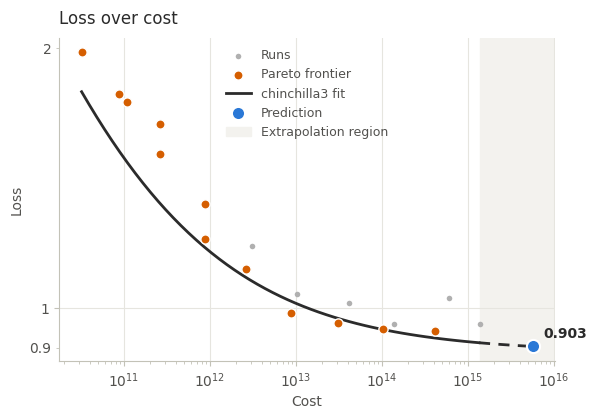

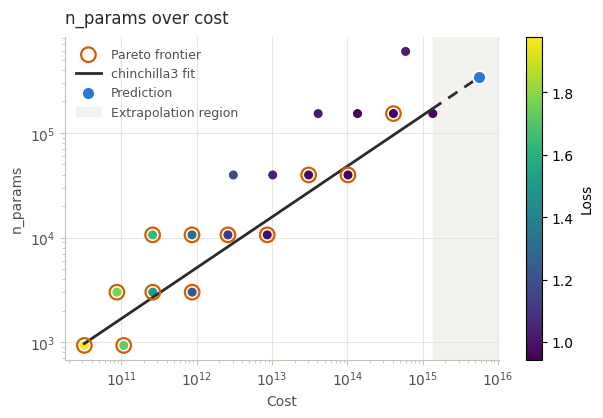

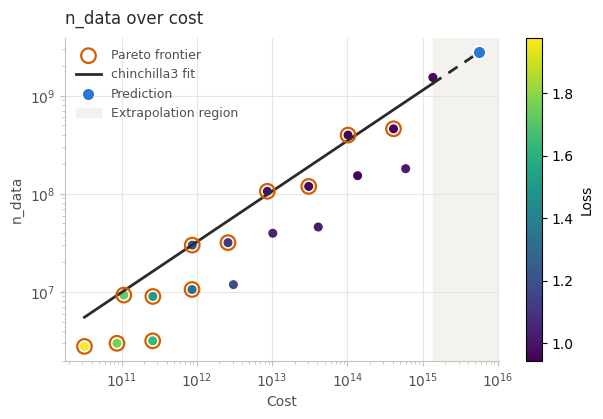

In [9]:
show(CHINCHILLA1 / "summary/pre_train/loss_over_cost.png",
     *[CHINCHILLA1 / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["n_params", "n_data"]])

The config is `None`: $L(N, D)$ knows only the model size and data, not the width,
the depth or the number of cells that make them up, nor the other hyperparameters.
The default pipeline below predicts a full config.

## 2. The default scaling pipeline

Without an `optimizer`, `acquire` uses random search: it samples configs of the
whole space, the hyperparameters included, each costing at most `max_cost_per_config`,
until the budget is spent. `predict` with its default `predictor="auto"` then fits
`power_law`, the predictor of random search, which also predicts every hyperparameter.

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory results/scaling_tutorial/default


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log

INFO:extrapolaw.runtime:Overwriting optimization directory 'results/scaling_tutorial/default' as `overwrite_optimization_dir=True`.


INFO:extrapolaw.runtime:Summary files can be found in the “summary” folder inside the root directory: /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/default/summary


INFO:extrapolaw.runtime:Using optimizer: random_search


INFO:extrapolaw.runtime:Worker 'worker_0' sampled new trial: 0.


... (175 outputs left out)

INFO:extrapolaw.runtime:Worker 'worker_0' evaluated trial: 58 as success.


INFO:extrapolaw.runtime:All workers together have reached the maximum cost allowed as given by `total_cost_to_spend=2800000000000000.0`. The total cost spent is '2800661938328243.0'.


INFO:extrapolaw.api:The summary folder has been created, with full.csv (all runs) and the plots.
You can find summary folder at: results/scaling_tutorial/default/summary.


C=5.6e+15: loss 0.570, N*=1.66e+06, D*=5.61e+08
config: {'effective_batch_size': 32, 'embedding_size': 8, 'lr': 0.0008256688597612083, 'num_layers': 2, 'total_cells': 34359738368}


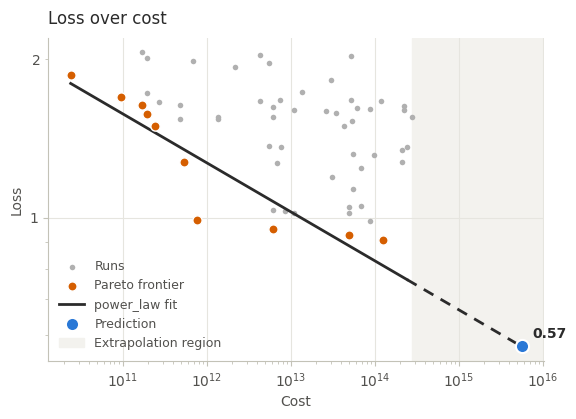

In [10]:
DEFAULT = RESULTS / "default"

tabpfn.set_seed(0)
extrapolaw.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNSpace(),
    root_directory=DEFAULT,
    cost_estimator=tabpfn.flops_estimator,
    max_cost_per_config=MAX_COST_PER_RUN,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

(prediction,) = extrapolaw.predict(DEFAULT, target_costs=TARGETS)
print(f"C={TARGET:.1e}: loss {prediction.loss:.3f},"
      f" N*={prediction.n_params:.2e}, D*={prediction.n_data:.2e}")
print("config:", prediction.config)
show(DEFAULT / "summary/pre_train/loss_over_cost.png")

### The individual hyperparameters

Every hyperparameter gets its own fit over the frontier runs, and a prediction at the
target:

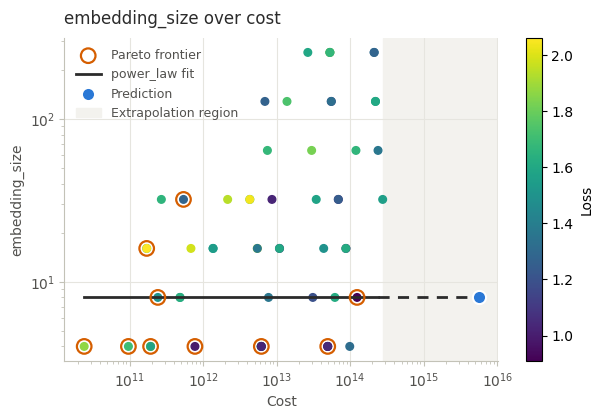

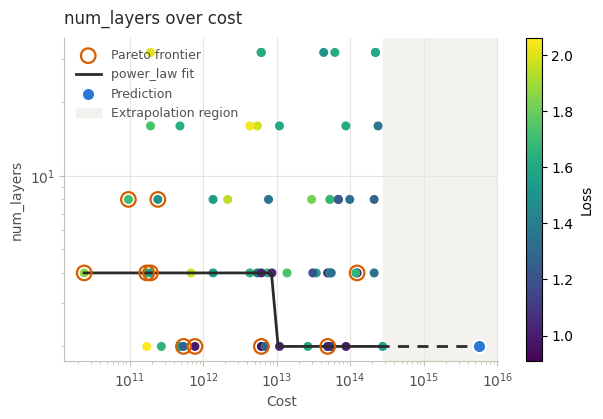

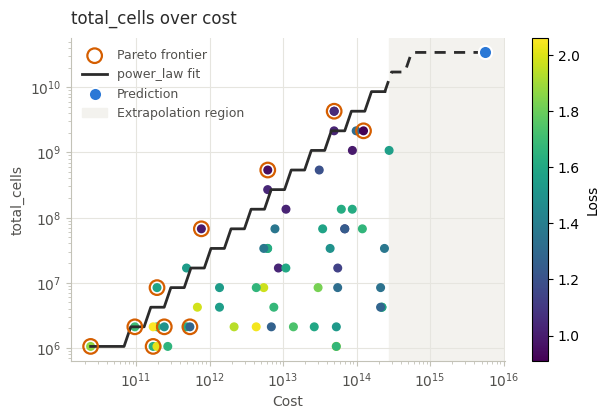

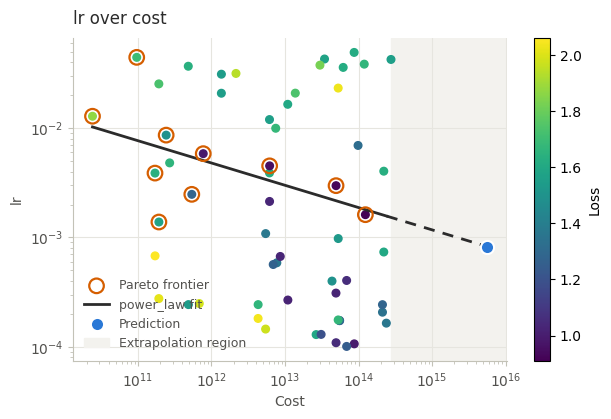

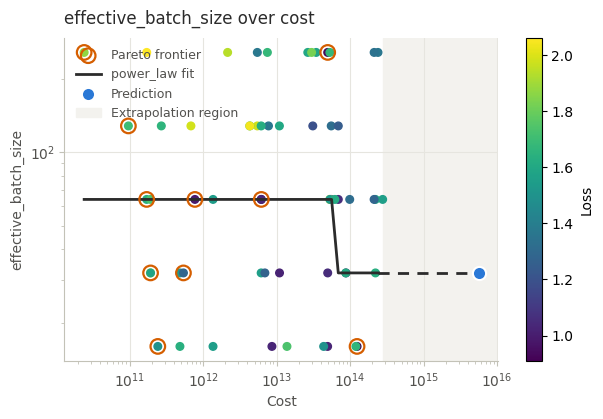

In [11]:
show(*[DEFAULT / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["embedding_size", "num_layers", "total_cells", "lr",
                    "effective_batch_size"]],
     width=420)

The prediction at each target, loss, model size, data and config, is saved as a
table next to the plots, as CSV and as text:

In [12]:
print((DEFAULT / "summary/pre_train/predictions_over_cost.txt").read_text())

 target_cost   loss  n_params    n_data  effective_batch_size  embedding_size        lr  num_layers  total_cells
     5.6e+15 0.5698 1.665e+06 5.606e+08                    32               8 0.0008257           2  34359738368



## 3. Downstream performance

Every metric in `downstream_performances` gets the same scaling fit and prediction as
the loss, here the NLL on real datasets:

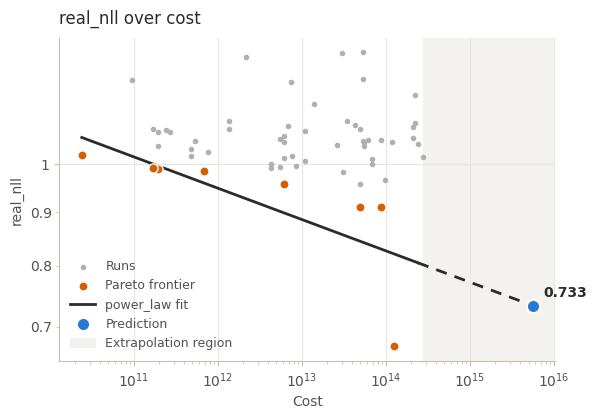

In [13]:
show(DEFAULT / "summary/downstream/real_nll/real_nll_over_cost.png")

## 4. Inference cost

When the runs report an `inference_cost`, the loss is also plotted over it, the best
loss a model of each inference cost reached:

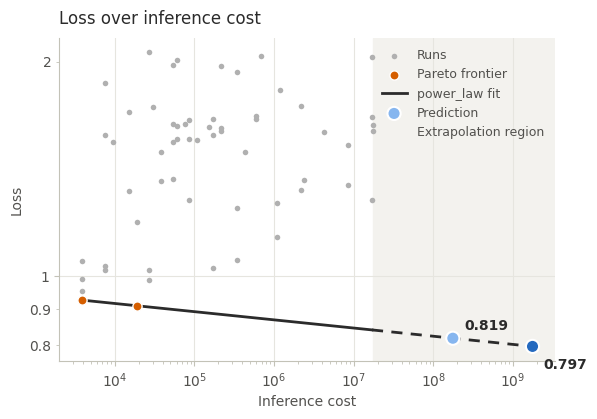

In [14]:
show(DEFAULT / "summary/pre_train/loss_over_inference_cost.png")

## 5. Parallel workers

A real study runs many trainings at once. With Extrapolaw you start the same
`acquire` call several times, as processes on the same machine, or as Slurm jobs on
different machines, all pointing at one `root_directory`: the workers share its FLOP
budget through the filesystem.

To give the runs a training time, `timed_evaluate_pipeline` waits as long as training
would take on a small simulated cluster. Below are three workers as processes of this
notebook (forked, as on Linux and Colab; on macOS or Windows run the `acquire` call
from a script in several terminals instead).

In [15]:
PARALLEL = RESULTS / "parallel"
shutil.rmtree(PARALLEL, ignore_errors=True)


def timed_evaluate_pipeline(**config) -> dict:
    """`evaluate_pipeline`, taking as long as training on the simulated cluster."""
    result = evaluate_pipeline(**config)
    time.sleep(result["cost"] / tabpfn.SIMULATED_FLOPS_PER_SECOND)
    return result


def run_worker():
    extrapolaw.acquire(
        evaluate_pipeline=timed_evaluate_pipeline,
        pipeline_space=TabPFNSpace(),
        root_directory=PARALLEL,
        cost_estimator=tabpfn.flops_estimator,
        max_cost_per_config=MAX_COST_PER_RUN,
        total_cost_to_spend=BUDGET,
    )


processes = [mp.Process(target=run_worker) for _ in range(3)]
for p in processes:
    p.start()
for p in processes:
    p.join()

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory results/scaling_tutorial/parallel


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory results/scaling_tutorial/parallel


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory results/scaling_tutorial/parallel


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log

... (233 outputs left out)

INFO:extrapolaw.state.pipeline_eval:Successful evaluation of '60': {'objective_to_minimize': 1.699, 'cost': 220690881445757.56, 'inference_cost': 17538935.45832297, 'n_params': 8538122, 'n_data': 4194304, 'downstream_performances': {'real_nll': 1.11}}.


INFO:extrapolaw.runtime:Worker 'worker_1' evaluated trial: 60 as success.


INFO:extrapolaw.runtime:All workers together have reached the maximum cost allowed as given by `total_cost_to_spend=2800000000000000.0`. The total cost spent is '3157538051210646.5'.


INFO:extrapolaw.api:The summary folder has been created, with full.csv (all runs) and the plots.
You can find summary folder at: results/scaling_tutorial/parallel/summary.


The three workers split the runs between them. Together they spent the budget (plus
the runs still training when it ran out) in about a third of the time the training
takes one after the other:

In [16]:
full, _ = extrapolaw.status(PARALLEL)
training_time = (full["cost"] / tabpfn.SIMULATED_FLOPS_PER_SECOND).sum()
wall_clock = full["time_end"].max() - full["time_sampled"].min()
print(f"{full['cost'].sum():.2e} FLOPs spent of {BUDGET:.2e}")
print(f"training time {training_time:.0f}s, wall clock {wall_clock:.0f}s")
full.groupby("evaluating_worker_id")["cost"].agg(runs="count", flops="sum")

3.16e+15 FLOPs spent of 2.80e+15
training time 158s, wall clock 55s


,runs,flops
evaluating_worker_id,,
worker_0,31,1034703418362171.75
worker_1,20,1064458022328559.5
worker_2,24,1058376610519914.625


## 6. Asynchronous sampling and multi-GPU jobs

On a cluster you rarely keep a worker alive for the whole study. Instead you sample
configs, hand each one to a job sized for it, and collect the results as the jobs
finish:

* With **`is_async=True`** and no `evaluate_pipeline`, `acquire` only samples. Each
  config is written to `configs/config_<id>/config.yaml` and stays pending.
* The job reads the config, trains it, and reports its result into the study with
  **`extrapolaw.save_pipeline_results`**.

A job can also train its config on several GPUs with **PyTorch DDP**: `torchrun`
starts one process per GPU, all of them train, and only rank 0 reports, so a
multi-GPU run is still one trial.

In [17]:
ASYNC = (RESULTS / "async").resolve()
shutil.rmtree(ASYNC, ignore_errors=True)


def sample(n_configs):
    """Sample `n_configs` configs, without training them."""
    extrapolaw.acquire(
        pipeline_space=TabPFNSpace(),
        root_directory=ASYNC,
        is_async=True,
        cost_estimator=tabpfn.flops_estimator,
        max_cost_per_config=MAX_COST_PER_RUN,
        total_cost_to_spend=BUDGET,
        # Pending configs have no cost yet, so bound each round by its size
        worker_evaluations_to_spend=n_configs,
    )


def pending_trials():
    """The ids of the sampled configs that have no result yet."""
    return [d.name.removeprefix("config_") for d in sorted(ASYNC.glob("configs/config_*"))
            if not (d / "report.yaml").exists()]


sample(4)
print("pending:", pending_trials())

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log

INFO:extrapolaw.runtime:Summary files can be found in the “summary” folder inside the root directory: /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async/summary


INFO:extrapolaw.runtime:Using optimizer: random_search


INFO:extrapolaw.runtime:Budget status - Evaluations: 0/4 (0%)


INFO:extrapolaw.runtime:Worker 'worker_0' sampled new trial: 0.


... (10 outputs left out)

INFO:extrapolaw.runtime:Budget status - Evaluations: 4/4 (100%)


INFO:extrapolaw.runtime:Worker has reached the maximum number of evaluations it is allowed to do as given by `self.settings.worker_evaluations_to_spend=4`.
To allow more evaluations, increase this value or use a different stopping criterion.


INFO:extrapolaw.api:The summary folder has been created, with full.csv (all runs) and the plots.
You can find summary folder at: /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async/summary.


pending: ['0', '1', '2', '3']


The job script, which reads its config from `config.yaml`. Every rank runs it, rank 0
reports. It reports the cost itself, as the `cost_estimator` of `acquire` only fills
in the cost of results returned by an `evaluate_pipeline`:

In [18]:
JOB = '''
import sys, time
import torch
import torch.distributed as dist
import yaml

import extrapolaw
import tabpfn_scan_bench as tabpfn

root, trial_id = sys.argv[1], sys.argv[2]
dist.init_process_group("gloo")  # "nccl" on GPUs
rank, world_size = dist.get_rank(), dist.get_world_size()

with open(f"{root}/configs/config_{trial_id}/config.yaml") as f:
    config = yaml.safe_load(f)
# Train: each rank works on its share of the batch, then the gradients are averaged
seconds = tabpfn.flops_estimator(**config) / tabpfn.SIMULATED_FLOPS_PER_SECOND
time.sleep(seconds / world_size)
gradient = torch.full((4,), float(rank))
dist.all_reduce(gradient)

if rank == 0:
    run = tabpfn.build_config(**config)
    result = {
        "objective_to_minimize": tabpfn.get_benchmark().query(run)["predictions"]["mean"],
        "cost": tabpfn.flops_estimator(**config),
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "info_dict": {"world_size": world_size},
    }
    extrapolaw.save_pipeline_results(result, pipeline_id=trial_id, root_directory=root)
dist.destroy_process_group()
'''
job_script = ASYNC / "job.py"
job_script.write_text(JOB)


def submit(trial_id, gpus=2):
    """Stands in for `sbatch`: runs the job on this machine, in the background."""
    env = {**os.environ, "PYTHONPATH": str(Path(tabpfn.__file__).parent)}
    return subprocess.Popen(
        [sys.executable, "-m", "torch.distributed.run", "--standalone",
         f"--nproc_per_node={gpus}", str(job_script), str(ASYNC), trial_id],
        env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )


def run_pending():
    """Submit a job for every pending config, and wait for their exit codes."""
    jobs = {trial_id: submit(trial_id) for trial_id in pending_trials()}
    return {trial_id: job.wait() for trial_id, job in jobs.items()}


print("round 1, exit codes:", run_pending())
sample(4)  # The next round, within the same budget
print("round 2, exit codes:", run_pending())

INFO:extrapolaw.api:Starting extrapolaw.acquire using root directory /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async


INFO:extrapolaw.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log

INFO:extrapolaw.runtime:Summary files can be found in the “summary” folder inside the root directory: /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async/summary


INFO:extrapolaw.runtime:Using optimizer: random_search


INFO:extrapolaw.runtime:Budget status - Evaluations: 0/4 (0%)


INFO:extrapolaw.runtime:Worker 'worker_1' sampled new trial: 4.


... (11 outputs left out)

INFO:extrapolaw.runtime:Worker has reached the maximum number of evaluations it is allowed to do as given by `self.settings.worker_evaluations_to_spend=4`.
To allow more evaluations, increase this value or use a different stopping criterion.


INFO:extrapolaw.api:The summary folder has been created, with full.csv (all runs) and the plots.
You can find summary folder at: /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async/summary.


round 1, exit codes: {'0': 0, '1': 0, '2': 0, '3': 0}


round 2, exit codes: {'4': 0, '5': 0, '6': 0, '7': 0}


Every job reported from rank 0 of its two processes, into the same study:

In [19]:
full, _ = extrapolaw.status(ASYNC)
full[["config.embedding_size", "config.num_layers", "config.total_cells",
      "objective_to_minimize", "cost", "extra.world_size"]].sort_values("cost")

,config.embedding_size,config.num_layers,config.total_cells,objective_to_minimize,cost,extra.world_size
id,,,,,,
5,4,32,4194304,1.866,769604386734.470093,2
4,4,8,16777216,1.291,770313298607.60437,2
7,4,2,134217728,1.362,1546297892200.282471,2
6,16,8,8388608,2.03,2727180131463.145508,2
0,4,8,268435456,1.067,12325012777721.669922,2
2,8,8,536870912,0.955,61956622142864.671875,2
3,64,2,134217728,0.957,119884358548080.234375,2
1,32,16,134217728,1.587,275663373223789.5625,2


## Takeaways

1. **Define** the pipeline and space, **acquire** runs within a FLOP budget,
   **predict** at the target compute.
2. **Predict** loss, model size and data, and a full config (`power_law` or
   `gp_posterior`; not `chinchilla3`), for the loss and every downstream metric.
3. Check the scaling plots in `summary/`, over the training and the inference cost.
4. **Scale out**: workers share one budget, async jobs report back, DDP works.